First 5 Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Species Distribution:
setosa        50
versicolor    50
virginica     50
Name: species, dtype: int64

Numerical Columns:
Ind

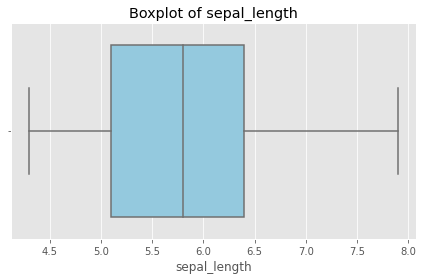

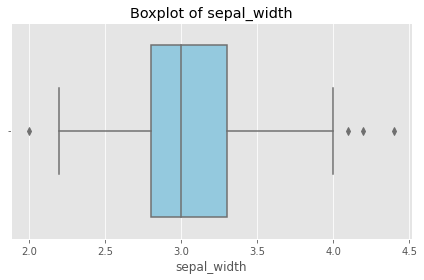

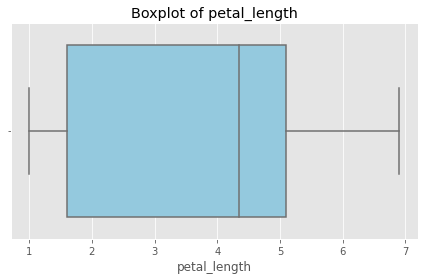

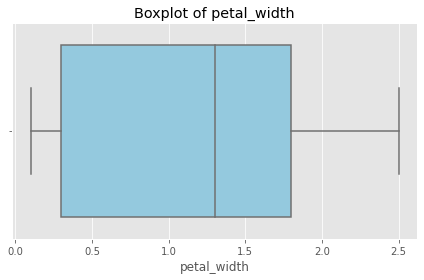

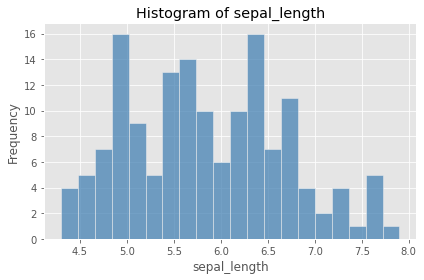

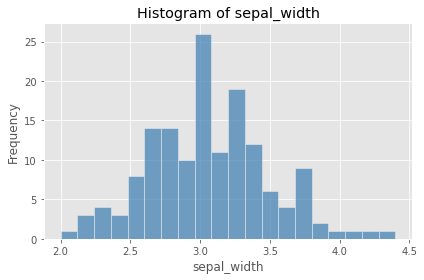

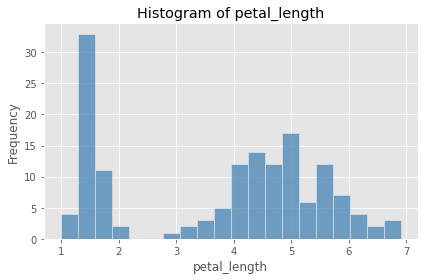

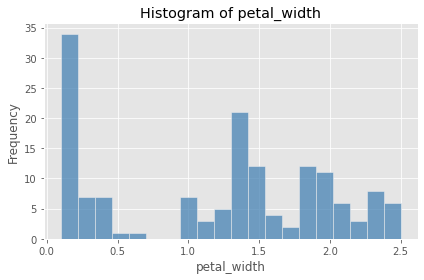

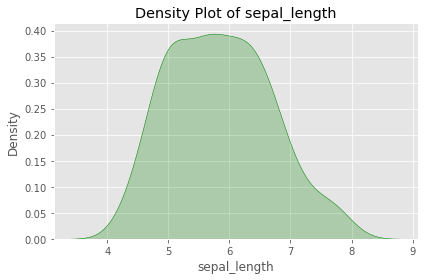

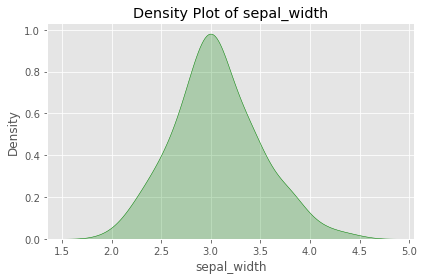

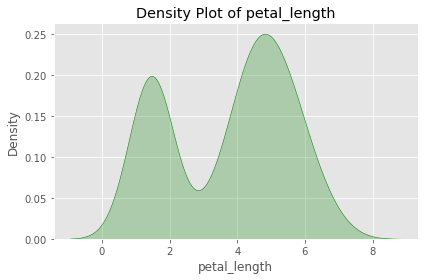

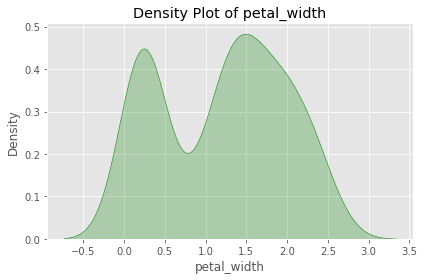

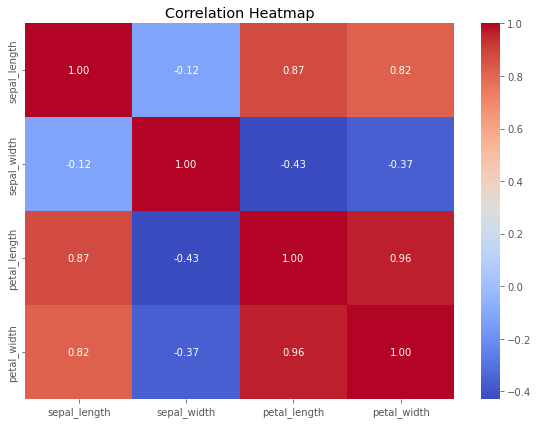

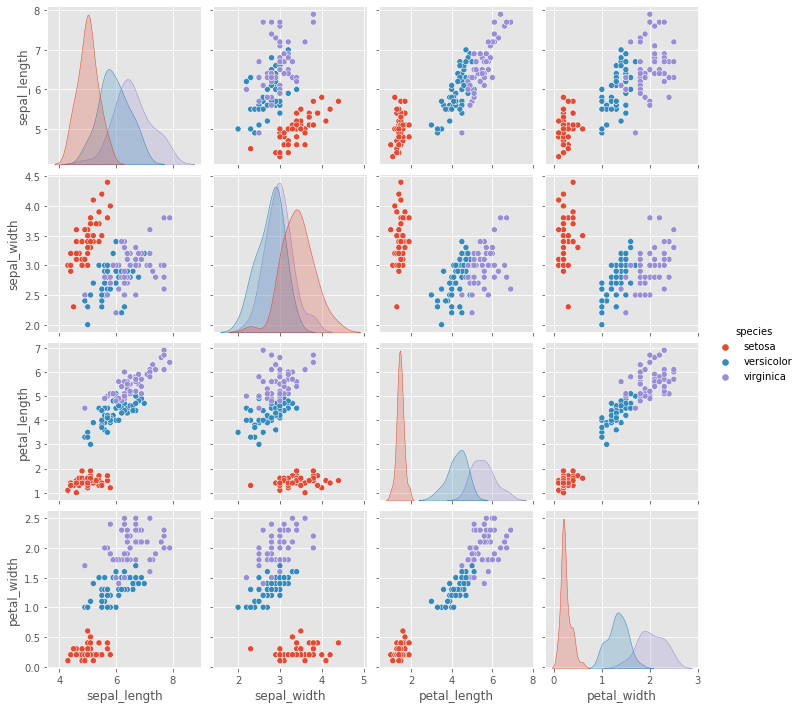

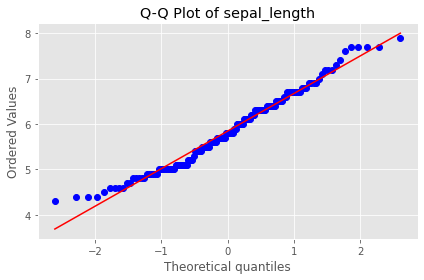

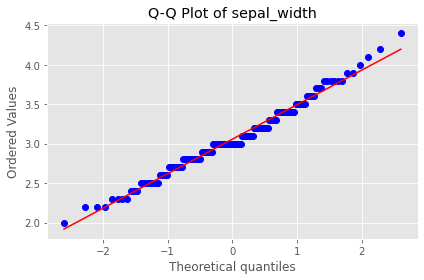

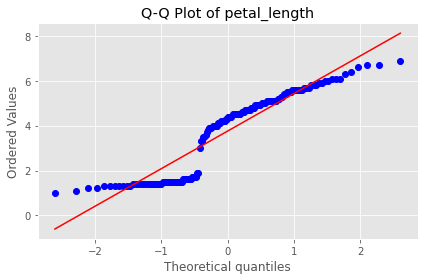

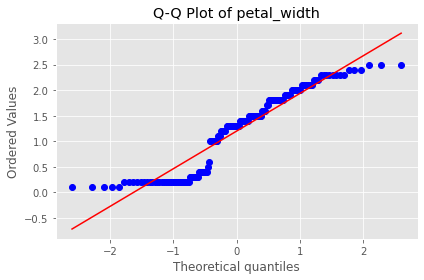


Analysis Completed Successfully!


In [1]:
# Install packages (Run once in Jupyter/Colab)
!pip install pandas numpy scipy matplotlib seaborn scikit-learn

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import trim_mean, median_abs_deviation
from scipy.stats import probplot
from sklearn.datasets import load_iris

# Plot style
plt.style.use('ggplot')

# ==========================
# LOAD IRIS DATASET
# ==========================
iris = load_iris(as_frame=True)

# Create DataFrame
df = iris.frame

# Rename target column
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.drop(columns=["target"], inplace=True)

# Rename columns for simplicity
df.columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

# Display first 5 rows
print("First 5 Rows:")
print(df.head())

# Display dataset information
print("\nDataset Info:")
print(df.info())

# Display species count
print("\nSpecies Distribution:")
print(df["species"].value_counts())

# Select only numerical columns
num_df = df.select_dtypes(include=np.number)

print("\nNumerical Columns:")
print(num_df.columns)

# -------------------------------
# DESCRIPTIVE STATISTICS
# -------------------------------
print("\n========== DESCRIPTIVE STATISTICS ==========\n")

for col in num_df.columns:
    data = num_df[col].dropna()

    print(f"\n----- {col} -----")

    print("Mean:", data.mean())
    print("Median:", data.median())
    print("Trimmed Mean:", trim_mean(data, 0.10))

    weights = np.arange(1, len(data)+1)
    print("Weighted Mean:", np.average(data, weights=weights))

    print("Range:", data.max() - data.min())
    print("Variance:", data.var())
    print("Standard Deviation:", data.std())

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    print("IQR:", IQR)

    print("Median Absolute Deviation:", median_abs_deviation(data))

# -------------------------------
# VISUALIZATIONS
# -------------------------------

# 1. Boxplots
for col in num_df.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=num_df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.show()

# 2. Histograms
for col in num_df.columns:
    plt.figure(figsize=(6,4))
    sns.histplot(num_df[col], bins=20, color='steelblue')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# 3. Density Plots
for col in num_df.columns:
    plt.figure(figsize=(6,4))
    sns.kdeplot(num_df[col], fill=True, color='green')
    plt.title(f'Density Plot of {col}')
    plt.tight_layout()
    plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(8,6))
sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# 5. Pair Plot
sns.pairplot(df, vars=num_df.columns, hue='species')
plt.show()

# 6. Q-Q Plots
for col in num_df.columns:
    plt.figure(figsize=(6,4))
    probplot(num_df[col].dropna(), dist="norm", plot=plt)
    plt.title(f'Q-Q Plot of {col}')
    plt.tight_layout()
    plt.show()

print("\nAnalysis Completed Successfully!")